# Protein group parsimony

Find every smallest protein set consistent with observed peptides.

Protein inference is a set-cover problem when each candidate protein contributes a set of peptide labels. Exhaustive enumeration is practical here and exposes ambiguity that a single greedy solution can conceal.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from peptide_methods import parsimony

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

minimum explanations [('A', 'B', 'D'), ('B', 'C', 'D')]


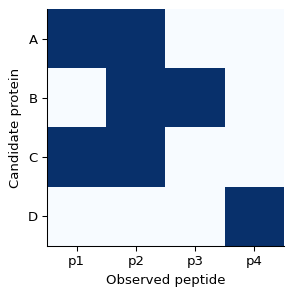

In [2]:
mapping = {"A": {"p1", "p2"}, "B": {"p2", "p3"}, "C": {"p1", "p2"}, "D": {"p4"}}
obs = {"p1", "p2", "p3", "p4"}
sol = parsimony(mapping, obs)
print("minimum explanations", sol)
assert sol == [("A", "B", "D"), ("B", "C", "D")]
fig, ax = plt.subplots(figsize=(5.4, 3), constrained_layout=True)
p = sorted(obs)
ax.imshow([[x in mapping[k] for x in p] for k in mapping], cmap="Blues", vmin=0, vmax=1)
ax.set(
    xticks=range(len(p)),
    xticklabels=p,
    yticks=range(len(mapping)),
    yticklabels=list(mapping),
    xlabel="Observed peptide",
    ylabel="Candidate protein",
)
plt.show()

## Interpreting the result

A and C are indistinguishable on the observed peptides. The minimum number of proteins is identifiable here, but their identities are partly ambiguous.

## Exercise

Add a peptide unique to A and repeat the enumeration.

## References

[Nesvizhskii and Aebersold, protein inference (2005)](https://doi.org/10.1074/mcp.R500012-MCP200)